In [22]:
import pandas as pd

In [24]:
df = pd.read_csv(
    "../data/consumption_processed.csv",
    sep=";",
    decimal=","
)

In [25]:
# Manglende verdier per kolonne
print(df.isna().sum())

# Antall identiske rader
print("Duplikater:", df.duplicated().sum())

# Duplikater av samme måling
print("Dupliserte målinger:", df.duplicated(
    subset=["STARTTID", "KOMMUNENUMMER", "FORBRUKSGRUPPE"]
).sum())


STARTTID            0
SLUTTID             0
KOMMUNE             0
KOMMUNENUMMER       0
FORBRUKSGRUPPE      0
VOLUM_KWH           0
ANTALL_MÅLEPUNKT    0
YEAR                0
MONTH               0
DAY                 0
HOUR                0
DAY_OF_WEEK         0
dtype: int64
Duplikater: 0
Dupliserte målinger: 0


In [26]:
# Negative strømforbruk
print(df[df["VOLUM_KWH"] < 0])

# Statistikk for strømforbruk
print(df["VOLUM_KWH"].describe())

# Strømforbruk per målepunkt
df["KWH_PER_PUNKT"] = df["VOLUM_KWH"] / df["ANTALL_MÅLEPUNKT"]

print(df["KWH_PER_PUNKT"].describe())


                           STARTTID                    SLUTTID KOMMUNE  \
316       2022-02-01 00:00:00+01:00  2022-02-01 01:00:00+01:00  Hemnes   
1390      2022-02-01 01:00:00+01:00  2022-02-01 02:00:00+01:00  Hemnes   
2464      2022-02-01 02:00:00+01:00  2022-02-01 03:00:00+01:00  Hemnes   
3538      2022-02-01 03:00:00+01:00  2022-02-01 04:00:00+01:00  Hemnes   
4612      2022-02-01 04:00:00+01:00  2022-02-01 05:00:00+01:00  Hemnes   
...                             ...                        ...     ...   
18358768  2024-01-14 05:00:00+01:00  2024-01-14 06:00:00+01:00   Tokke   
18359842  2024-01-14 06:00:00+01:00  2024-01-14 07:00:00+01:00   Tokke   
18360916  2024-01-14 07:00:00+01:00  2024-01-14 08:00:00+01:00   Tokke   
18377026  2024-01-14 22:00:00+01:00  2024-01-14 23:00:00+01:00   Tokke   
18378100  2024-01-14 23:00:00+01:00  2024-01-15 00:00:00+01:00   Tokke   

          KOMMUNENUMMER FORBRUKSGRUPPE  VOLUM_KWH  ANTALL_MÅLEPUNKT  YEAR  \
316                1832       Indu

In [27]:
# Manglende eller ugyldige målepunkter
print(df[df["ANTALL_MÅLEPUNKT"] <= 0])

# Statistikk
print(df["ANTALL_MÅLEPUNKT"].describe())

Empty DataFrame
Columns: [STARTTID, SLUTTID, KOMMUNE, KOMMUNENUMMER, FORBRUKSGRUPPE, VOLUM_KWH, ANTALL_MÅLEPUNKT, YEAR, MONTH, DAY, HOUR, DAY_OF_WEEK, KWH_PER_PUNKT]
Index: []
count    3.995173e+07
mean     3.132711e+03
std      1.341891e+04
min      5.000000e+00
25%      1.880000e+02
50%      5.130000e+02
75%      2.192000e+03
max      3.573210e+05
Name: ANTALL_MÅLEPUNKT, dtype: float64


In [28]:
# Vis de 10 høyeste verdiene per målepunkt
print(df.nlargest(10, "KWH_PER_PUNKT")[
    ["KOMMUNE", "FORBRUKSGRUPPE", "VOLUM_KWH",
     "ANTALL_MÅLEPUNKT", "KWH_PER_PUNKT"]
])


          KOMMUNE FORBRUKSGRUPPE     VOLUM_KWH  ANTALL_MÅLEPUNKT  \
39535651  Orkland       Industri  1.256062e+07               617   
39531355  Orkland       Industri  1.256051e+07               617   
39532429  Orkland       Industri  1.256029e+07               617   
39533503  Orkland       Industri  1.256028e+07               617   
39534577  Orkland       Industri  1.256007e+07               617   
39536725  Orkland       Industri  1.255976e+07               617   
39538873  Orkland       Industri  1.255869e+07               617   
39537799  Orkland       Industri  1.255639e+07               617   
5462329     Årdal       Industri  4.019446e+05                58   
5455885     Årdal       Industri  3.990492e+05                58   

          KWH_PER_PUNKT  
39535651   20357.567287  
39531355   20357.398575  
39532429   20357.031937  
39533503   20357.017574  
39534577   20356.680486  
39536725   20356.170355  
39538873   20354.443776  
39537799   20350.705313  
5462329     6930.

In [29]:
# Negative målinger per forbruksgruppe
print(df[df["VOLUM_KWH"] < 0]["FORBRUKSGRUPPE"].value_counts())

# Negative målinger per kommune
print(df[df["VOLUM_KWH"] < 0]["KOMMUNE"].value_counts())


FORBRUKSGRUPPE
Industri      3186
Forretning     137
Privat          24
Name: count, dtype: int64
KOMMUNE
Tokke                 3153
Storfjord               89
Hábmer                  33
Leka                    32
Hemnes                  24
Ukjent tilhørighet      15
Oppdal                   1
Name: count, dtype: int64


In [30]:
print(df.nlargest(10, "VOLUM_KWH")[
    ["STARTTID", "KOMMUNE", "VOLUM_KWH"]
])


                           STARTTID  KOMMUNE     VOLUM_KWH
39535651  2026-04-14 20:00:00+02:00  Orkland  1.256062e+07
39531355  2026-04-14 16:00:00+02:00  Orkland  1.256051e+07
39532429  2026-04-14 17:00:00+02:00  Orkland  1.256029e+07
39533503  2026-04-14 18:00:00+02:00  Orkland  1.256028e+07
39534577  2026-04-14 19:00:00+02:00  Orkland  1.256007e+07
39536725  2026-04-14 21:00:00+02:00  Orkland  1.255976e+07
39538873  2026-04-14 23:00:00+02:00  Orkland  1.255869e+07
39537799  2026-04-14 22:00:00+02:00  Orkland  1.255639e+07
18192059  2024-01-07 18:00:00+01:00     Oslo  1.110606e+06
18190985  2024-01-07 17:00:00+01:00     Oslo  1.109595e+06


In [31]:
negative = df[df["VOLUM_KWH"] < 0]

print(negative.groupby(["KOMMUNE", "YEAR"]).size())

KOMMUNE             YEAR
Hemnes              2022      24
Hábmer              2023      33
Leka                2022      32
Oppdal              2022       1
Storfjord           2022      89
Tokke               2022    3116
                    2024      37
Ukjent tilhørighet  2023      15
dtype: int64


<Axes: xlabel='STARTTID'>

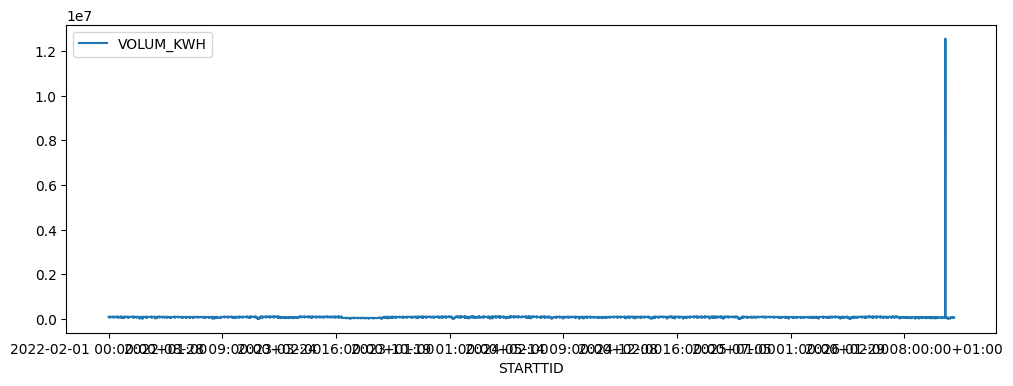

In [32]:
orkland = df[
    (df["KOMMUNE"] == "Orkland") &
    (df["FORBRUKSGRUPPE"] == "Industri")
]

orkland.plot(x="STARTTID", y="VOLUM_KWH", figsize=(12, 4))

<Axes: xlabel='STARTTID'>

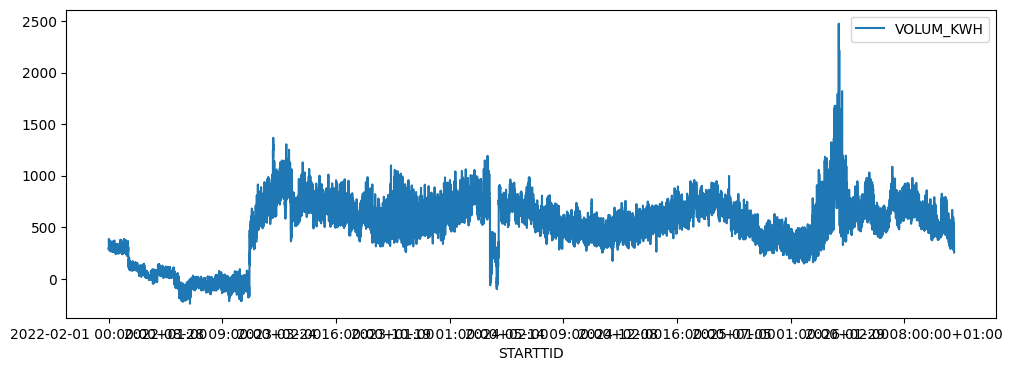

In [33]:
tokke = df[
    (df["KOMMUNE"] == "Tokke") &
    (df["FORBRUKSGRUPPE"] == "Industri")
]

tokke.plot(x="STARTTID", y="VOLUM_KWH", figsize=(12, 4))

In [34]:
# Finn mistenkelige verdier i Orkland
feil = (
    (df["KOMMUNE"] == "Orkland") &
    (df["FORBRUKSGRUPPE"] == "Industri") &
    (df["VOLUM_KWH"] > 10_000_000)
)

print("Mulige feil:", feil.sum())


Mulige feil: 8


<Axes: xlabel='STARTTID'>

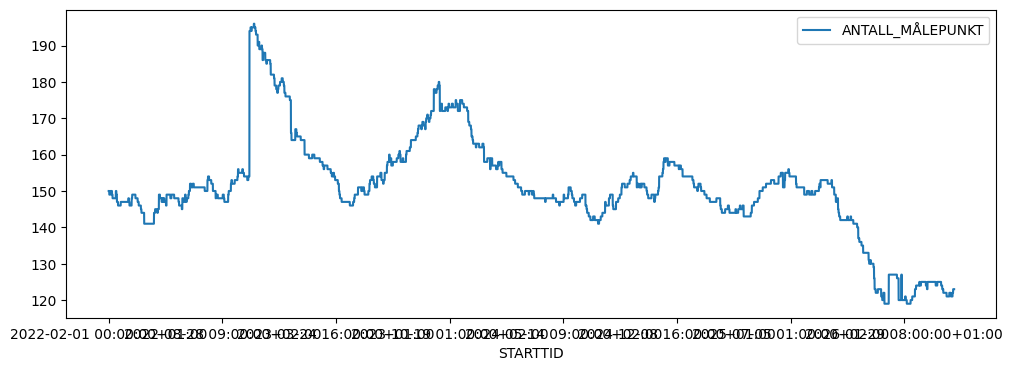

In [35]:
tokke.plot(
    x="STARTTID",
    y="ANTALL_MÅLEPUNKT",
    figsize=(12, 4)
)


In [36]:
df = df[~(
    (df["KOMMUNE"] == "Orkland") &
    (df["FORBRUKSGRUPPE"] == "Industri") &
    (df["VOLUM_KWH"] > 10_000_000)
)].copy()


Eight observations from Orkland on April 14, 2026, were removed due to exceptionally high electricity consumption values of approximately 12.56 million kWh per hour. These values differed substantially from the municipality's normal consumption pattern and were treated as likely data errors.

Negative consumption values were retained because their cause could not be determined with certainty.

In [38]:
# Konverter tidspunktene til UTC
tid = pd.to_datetime(df["STARTTID"], utc=True)

# Konverter deretter til norsk tid
norsk_tid = tid.dt.tz_convert("Europe/Oslo")

print(norsk_tid.head())


0   2022-02-01 00:00:00+01:00
1   2022-02-01 00:00:00+01:00
2   2022-02-01 00:00:00+01:00
3   2022-02-01 00:00:00+01:00
4   2022-02-01 00:00:00+01:00
Name: STARTTID, dtype: datetime64[ns, Europe/Oslo]


In [39]:

# Unike timer per dag
timer = pd.DataFrame({"tid": norsk_tid.drop_duplicates()})
timer["dato"] = timer["tid"].dt.date

# Tell timer per dag
timer_per_dag = timer.groupby("dato").size()

# Vis dager med 23 eller 25 timer
print(timer_per_dag[timer_per_dag.isin([23, 25])])


dato
2022-03-27    23
2022-10-30    25
2023-03-26    23
2023-10-29    25
2024-03-31    23
2024-10-27    25
2025-03-30    23
2025-10-26    25
2026-03-29    23
dtype: int64


Kommune endringer

In [40]:

# Kommuner som har hatt flere kommunenummer
kommuner = df.groupby("KOMMUNE")["KOMMUNENUMMER"].nunique()

print(kommuner[kommuner > 1])


KOMMUNE
Herøy    2
Våler    2
Name: KOMMUNENUMMER, dtype: int64


In [41]:

# Kommunenummer som har hatt flere navn
nummer = df.groupby("KOMMUNENUMMER")["KOMMUNE"].nunique()

print(nummer[nummer > 1])


Series([], Name: KOMMUNE, dtype: int64)


In [42]:

# Antall forskjellige kommunenumre per år
print(df.groupby("YEAR")["KOMMUNENUMMER"].nunique())


YEAR
2022    358
2023    358
2024    358
2025    358
2026    358
Name: KOMMUNENUMMER, dtype: int64


In [43]:

# Kommunenumre i 2022 og 2026
kommune_2022 = set(df[df["YEAR"] == 2022]["KOMMUNENUMMER"])
kommune_2026 = set(df[df["YEAR"] == 2026]["KOMMUNENUMMER"])

print("Forsvunnet:", kommune_2022 - kommune_2026)
print("Nye:", kommune_2026 - kommune_2022)


Forsvunnet: set()
Nye: set()


In [44]:

# Sjekk om alle år har de samme kommunenumrene
kommuner_2022 = set(df[df["YEAR"] == 2022]["KOMMUNENUMMER"])

for år in df["YEAR"].unique():
    kommuner = set(df[df["YEAR"] == år]["KOMMUNENUMMER"])
    print(år, kommuner == kommuner_2022)


2022 True
2023 True
2024 True
2025 True
2026 True


## Data Quality Assessment

The dataset contains approximately 40 million hourly electricity consumption records from 2022 to 2026. Several data quality checks were performed before analysis.

- **Missing values and duplicates:** No missing values or duplicate records were identified.
- **Outliers:** Eight extreme observations in Orkland on April 14, 2026, were removed. These showed unusually high consumption of approximately 12.56 million kWh per hour.
- **Negative consumption:** 3,347 negative values were identified, mainly in industrial consumption in Tokke. These were retained because they may represent actual measurements or differences in reporting.
- **Metering points:** No zero or negative metering point counts were found.
- **Missing hours:** No missing hourly timestamps were identified.
- **Daylight saving time:** The dataset correctly contains 23 hours during the spring transition and 25 hours during the autumn transition.
- **Municipalities:** The same 358 municipality codes were present throughout 2022–2026. Herøy and Våler each refer to two different municipalities with the same name. Municipality codes will therefore be used as identifiers. Historical boundary changes were not independently verified.

**Conclusion:** The dataset appears suitable for further analysis after removing the eight extreme observations. Negative consumption values and potential changes in municipality boundaries remain limitations that should be considered when interpreting the results.